# ClimaCidadão — previsão de risco térmico na próxima hora
**Pergunta de ML:** a partir das condições meteorológicas atuais da estação A701, é possível prever se a próxima hora terá risco térmico?

Modelo: Random Forest de classificação. Dados reais e públicos do INMET; nenhuma linha simulada.

In [1]:
from pathlib import Path
import hashlib, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, accuracy_score
from sklearn.inspection import permutation_importance
RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)


In [2]:
files = sorted(p for p in Path('dados').iterdir() if p.is_file() and p.suffix.lower() == '.csv')
assert files, 'Baixe e extraia os CSVs oficiais conforme dados/README.md'
print('Arquivos:', len(files))
for p in files: print(p.name, hashlib.sha256(p.read_bytes()).hexdigest()[:16])

def read_inmet(path):
    raw = path.read_text(encoding='latin1', errors='replace').splitlines()
    header = next(i for i, line in enumerate(raw) if 'Data' in line and ';' in line)
    df = pd.read_csv(path, sep=';', decimal=',', encoding='latin1', skiprows=header)
    df.columns = [re.sub(r'[^a-z0-9]+','_', c.lower().encode('ascii','ignore').decode()).strip('_') for c in df.columns]
    return df
raw = pd.concat([read_inmet(p) for p in files], ignore_index=True)
print(raw.shape); display(raw.head())


Arquivos: 2
INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2024_A_31-12-2024.CSV c5f365c069258734
INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025.CSV 1eac048271dd0339
(17544, 20)


,data,hora_utc,precipitao_total_horrio_mm,pressao_atmosferica_ao_nivel_da_estacao_horaria_mb,presso_atmosferica_max_na_hora_ant_aut_mb,presso_atmosferica_min_na_hora_ant_aut_mb,radiacao_global_kj_m,temperatura_do_ar_bulbo_seco_horaria_c,temperatura_do_ponto_de_orvalho_c,temperatura_mxima_na_hora_ant_aut_c,temperatura_mnima_na_hora_ant_aut_c,temperatura_orvalho_max_na_hora_ant_aut_c,temperatura_orvalho_min_na_hora_ant_aut_c,umidade_rel_max_na_hora_ant_aut,umidade_rel_min_na_hora_ant_aut,umidade_relativa_do_ar_horaria,vento_direo_horaria_gr_gr,vento_rajada_maxima_m_s,vento_velocidade_horaria_m_s,unnamed_19
0,2024/01/01,0000 UTC,0.0,926.9,926.9,926.4,NaN,19.5,15.0,19.9,19.4,15.2,14.5,76.0,71.0,75.0,161.0,8.8,3.4,NaN
1,2024/01/01,0100 UTC,0.0,927.6,927.6,926.9,NaN,19.3,14.8,19.6,19.3,15.0,14.7,76.0,74.0,75.0,156.0,8.8,3.0,NaN
2,2024/01/01,0200 UTC,0.0,927.1,927.7,927.1,NaN,19.0,14.6,19.4,19.0,14.9,14.6,76.0,75.0,75.0,151.0,8.1,3.0,NaN
3,2024/01/01,0300 UTC,0.0,927.2,927.3,927.0,NaN,19.2,13.8,19.2,19.0,14.6,13.7,75.0,71.0,71.0,150.0,6.7,2.1,NaN
4,2024/01/01,0400 UTC,0.0,926.3,927.2,926.3,NaN,18.9,13.4,19.2,18.8,13.8,13.3,71.0,69.0,70.0,143.0,6.3,2.2,NaN


In [3]:
def find_col(words):
    for c in raw.columns:
        if all(w in c for w in words): return c
    raise KeyError(words)
date_col=find_col(['data']); hour_col=find_col(['hora']); temp_col=find_col(['temperatura','bulbo','horaria']); hum_col=find_col(['umidade','relativa','horaria']); press_col=find_col(['pressao','atmosferica','horaria']); wind_col=find_col(['vento','velocidade'])
df=pd.DataFrame({'date':raw[date_col], 'hour':raw[hour_col], 'temp':raw[temp_col], 'humidity':raw[hum_col], 'pressure':raw[press_col], 'wind':raw[wind_col]})
for c in ['temp','humidity','pressure','wind']: df[c]=pd.to_numeric(df[c],errors='coerce').replace(9999,np.nan)
df['datetime']=pd.to_datetime(df['date'].astype(str)+' '+df['hour'].astype(str).str.extract(r'(\d{2})',expand=False)+':00',errors='coerce',utc=True)
df=df.dropna().sort_values('datetime').drop_duplicates('datetime').reset_index(drop=True)
# Alvo operacional: próxima hora com temperatura >=30 C. O limiar representa calor elevado e mantém casos positivos nos blocos temporais.
df['target']=(df['temp'].shift(-1)>=30).astype(int)
df=df.iloc[:-1].copy()
df['hour_sin']=np.sin(2*np.pi*df.datetime.dt.hour/24); df['hour_cos']=np.cos(2*np.pi*df.datetime.dt.hour/24)
df['month_sin']=np.sin(2*np.pi*df.datetime.dt.month/12); df['month_cos']=np.cos(2*np.pi*df.datetime.dt.month/12)
print(df.datetime.min(), df.datetime.max(), df.shape, df.target.value_counts(normalize=True)); display(df.describe())


2024-01-01 00:00:00+00:00 2025-12-31 22:00:00+00:00 (17477, 12) target
0    0.954512
1    0.045488
Name: proportion, dtype: float64


,temp,humidity,pressure,wind,target,hour_sin,hour_cos,month_sin,month_cos
count,17477.000000,17477.000000,17477.000000,17477.000000,17477.000000,17477.000000,1.747700e+04,1.747700e+04,1.747700e+04
mean,21.021983,67.380100,927.425330,1.712651,0.045488,0.000051,-7.582212e-05,-5.263069e-03,-2.357567e-03
std,4.784176,18.102279,3.662787,1.101104,0.208379,0.707157,7.070967e-01,7.060344e-01,7.081945e-01
min,5.800000,12.000000,913.400000,0.000000,0.000000,-1.000000,-1.000000e+00,-1.000000e+00,-1.000000e+00
25%,17.700000,55.000000,924.900000,1.000000,0.000000,-0.707107,-7.071068e-01,-8.660254e-01,-8.660254e-01
50%,20.800000,73.000000,927.100000,1.700000,0.000000,0.000000,-1.836970e-16,-2.449294e-16,-1.836970e-16
75%,24.000000,81.000000,929.900000,2.400000,0.000000,0.707107,7.071068e-01,5.000000e-01,8.660254e-01
max,35.900000,100.000000,938.200000,10.000000,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000e+00


In [4]:
features=['temp','humidity','pressure','wind','hour_sin','hour_cos','month_sin','month_cos']
cut=int(len(df)*.8)
train,test=df.iloc[:cut],df.iloc[cut:]
X_train,y_train=train[features],train.target; X_test,y_test=test[features],test.target
assert train.datetime.max()<test.datetime.min(), 'Vazamento temporal'
print('Treino',train.datetime.min(),train.datetime.max(),len(train)); print('Teste',test.datetime.min(),test.datetime.max(),len(test))


Treino 2024-01-01 00:00:00+00:00 2025-08-07 06:00:00+00:00 13981
Teste 2025-08-07 07:00:00+00:00 2025-12-31 22:00:00+00:00 3496


In [5]:
params={'n_estimators':[100,200,300,500], 'max_depth':[4,8,12,None], 'min_samples_leaf':[1,2,5,10]} # 3 hiperparâmetros
# Três blocos expansivos preservam a ordem temporal e contêm positivos em todas as validações.
search=RandomizedSearchCV(RandomForestClassifier(class_weight='balanced',random_state=RANDOM_STATE,n_jobs=-1), params, n_iter=10, scoring='f1', cv=TimeSeriesSplit(3), random_state=RANDOM_STATE, n_jobs=-1, return_train_score=True)
search.fit(X_train,y_train)
print('Melhores parâmetros:',search.best_params_,'CV F1:',search.best_score_)
results=pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
display(results[['params','mean_train_score','mean_test_score','std_test_score']])


Melhores parâmetros: {'n_estimators': 100, 'min_samples_leaf': 2, 'max_depth': 12} CV F1: 0.6989399953255035


,params,mean_train_score,mean_test_score,std_test_score
5,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",0.900087,0.698940,0.156086
0,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",0.934237,0.689482,0.183624
1,"{'n_estimators': 300, 'min_samples_leaf': 5, '...",0.848874,0.686722,0.173599
6,"{'n_estimators': 100, 'min_samples_leaf': 1, '...",0.837410,0.667541,0.196608
8,"{'n_estimators': 200, 'min_samples_leaf': 5, '...",0.816403,0.663849,0.195062
3,"{'n_estimators': 100, 'min_samples_leaf': 10, ...",0.796184,0.658306,0.172798
9,"{'n_estimators': 200, 'min_samples_leaf': 10, ...",0.797135,0.657919,0.172672
4,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.718345,0.575743,0.222265
2,"{'n_estimators': 100, 'min_samples_leaf': 1, '...",0.721556,0.574720,0.224885
7,"{'n_estimators': 100, 'min_samples_leaf': 10, ...",0.715762,0.571668,0.219428


,conjunto,accuracy,precision,recall,f1
0,treino,0.985623,0.758993,1.00000,0.862986
1,teste,0.978261,0.704762,0.91358,0.795699


              precision    recall  f1-score   support

           0       1.00      0.98      0.99      3334
           1       0.70      0.91      0.80       162

    accuracy                           0.98      3496
   macro avg       0.85      0.95      0.89      3496
weighted avg       0.98      0.98      0.98      3496



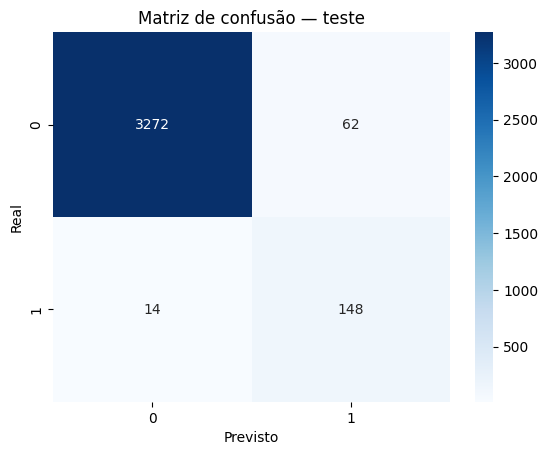

In [6]:
model=search.best_estimator_
def metrics(X,y,label):
    pred=model.predict(X); return {'conjunto':label,'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0)}
summary=pd.DataFrame([metrics(X_train,y_train,'treino'),metrics(X_test,y_test,'teste')]); display(summary)
pred=model.predict(X_test); print(classification_report(y_test,pred,zero_division=0))
sns.heatmap(confusion_matrix(y_test,pred),annot=True,fmt='d',cmap='Blues'); plt.title('Matriz de confusão — teste'); plt.xlabel('Previsto'); plt.ylabel('Real'); plt.show()


temp         0.700848
humidity     0.502060
hour_cos     0.104298
hour_sin     0.057861
pressure     0.002155
month_cos   -0.004067
month_sin   -0.010094
wind        -0.014847
Name: queda_media_f1, dtype: float64

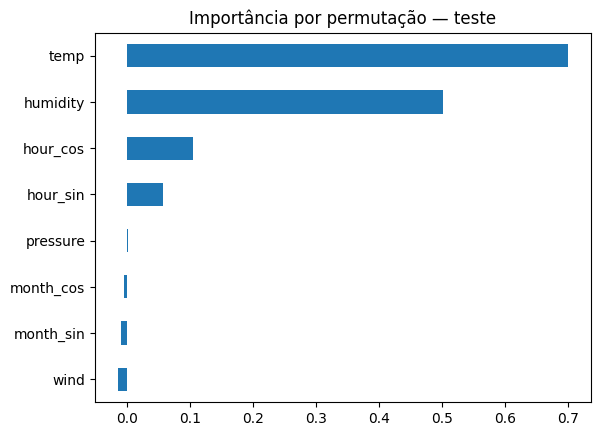

Gap F1 treino-teste: 0.067


In [7]:
importance=permutation_importance(model,X_test,y_test,n_repeats=10,random_state=RANDOM_STATE,scoring='f1')
importance_series=pd.Series(importance.importances_mean,index=features).sort_values()
display(importance_series.sort_values(ascending=False).rename('queda_media_f1'))
importance_series.plot.barh(title='Importância por permutação — teste'); plt.show()
print('Gap F1 treino-teste:',round(summary.loc[0,'f1']-summary.loc[1,'f1'],3))


## Conclusão a preencher após execução

Copie as métricas reais para `RELATORIO_ML.md`. Discuta falsos negativos (alerta perdido), falsos positivos (fadiga de alerta), desbalanceamento e gap treino–teste. Não afirme previsão clínica: o alvo é uma regra operacional experimental e alertas oficiais prevalecem.